In [1]:
import os
import pickle
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.applications import MobileNet, MobileNetV2, DenseNet121, ResNet50
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score, roc_curve, auc
)
from sklearn.preprocessing import label_binarize

# === Dataset Paths ===
train_dir = 'plntdata/Final_DataSet/train'
val_dir = 'plntdata/Final_DataSet/valid'

# === Constants ===
IMG_SIZE = (224, 224)
BATCH_SIZE = 96
EPOCHS = 25  # increase after testing

# === Data Generators ===
train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen   = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

val_gen = val_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

# === Early Stopping ===
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# === Plot Accuracy & Loss ===
def plot_accuracy_loss(history_dict, model_name):
    plt.figure(figsize=(12, 5))

    # Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(history_dict['accuracy'], label='Train Accuracy')
    plt.plot(history_dict['val_accuracy'], label='Validation Accuracy')
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title("Epoch vs Accuracy")
    plt.legend()

    # Loss
    plt.subplot(1, 2, 2)
    plt.plot(history_dict['loss'], label='Train Loss')
    plt.plot(history_dict['val_loss'], label='Validation Loss')
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Epoch vs Loss")
    plt.legend()

    plt.tight_layout()
    plt.savefig(f"{model_name}_Accuracy_Loss.png")
    plt.show()

# === Plot Multi-Class ROC ===
def plot_multiclass_roc(y_true, y_probs, class_names, model_name):
    y_true_bin = label_binarize(y_true, classes=range(len(class_names)))
    fpr, tpr, roc_auc = {}, {}, {}

    for i in range(len(class_names)):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_probs[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    plt.figure(figsize=(10, 8))
    for i in range(len(class_names)):
        plt.plot(fpr[i], tpr[i], label=f'{class_names[i]} (AUC = {roc_auc[i]:.2f})')

    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Multi-Class ROC Curve')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.savefig(f"{model_name}_ROC_Curve.png")
    plt.show()

# === Main Training & Evaluation ===
def train_and_evaluate_model(model_fn, model_name):
    print(f"\n=== Training {model_name} ===")

    # Base model
    base_model = model_fn(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
    base_model.trainable = False

    # Full model
    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(train_gen.num_classes, activation='softmax')
    ])

    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

    # Train model
    history = model.fit(
        train_gen,
        validation_data=val_gen,
        epochs=EPOCHS,
        callbacks=[early_stop],
        verbose=2
    )

    # Save history with pickle
    with open(f'{model_name}_history.pkl', 'wb') as f:
        pickle.dump(history.history, f)
    print(f"✅ Training history saved as {model_name}_history.pkl")

    # Save model
    model.save(f"{model_name}_full_model.h5")
    print(f"✅ Saved full model as {model_name}_full_model.h5")

    # Predict & evaluate
    val_gen.reset()
    preds = model.predict(val_gen)
    y_pred = np.argmax(preds, axis=1)
    y_true = val_gen.classes
    class_names = list(val_gen.class_indices.keys())

    # Classification Report
    print(f"\n📊 Classification Report for {model_name}:")
    print(classification_report(y_true, y_pred, target_names=class_names))

    # Additional Metrics
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)

    print(f"✅ Accuracy:  {acc:.4f}")
    print(f"✅ Precision: {prec:.4f}")
    print(f"✅ Recall:    {rec:.4f}")
    print(f"✅ F1 Score:  {f1:.4f}")

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt="d", xticklabels=class_names, yticklabels=class_names, cmap="Blues")
    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.savefig(f"{model_name}_confusion_matrix.png")
    plt.show()

    # Plots
    plot_accuracy_loss(history.history, model_name)
    plot_multiclass_roc(y_true, preds, class_names, model_name)

    return history, acc, prec, rec, f1


Found 70295 images belonging to 38 classes.
Found 17572 images belonging to 38 classes.



=== Training MobileNetV1 ===
Epoch 1/25
733/733 - 195s - loss: 0.8458 - accuracy: 0.7538 - val_loss: 0.1969 - val_accuracy: 0.9417 - 195s/epoch - 266ms/step
Epoch 2/25
733/733 - 173s - loss: 0.3317 - accuracy: 0.8941 - val_loss: 0.1430 - val_accuracy: 0.9537 - 173s/epoch - 235ms/step
Epoch 3/25
733/733 - 184s - loss: 0.2616 - accuracy: 0.9150 - val_loss: 0.1123 - val_accuracy: 0.9612 - 184s/epoch - 251ms/step
Epoch 4/25
733/733 - 181s - loss: 0.2240 - accuracy: 0.9260 - val_loss: 0.1070 - val_accuracy: 0.9620 - 181s/epoch - 248ms/step
Epoch 5/25
733/733 - 182s - loss: 0.2015 - accuracy: 0.9329 - val_loss: 0.1013 - val_accuracy: 0.9661 - 182s/epoch - 248ms/step
Epoch 6/25
733/733 - -19612s - loss: 0.1865 - accuracy: 0.9370 - val_loss: 0.0950 - val_accuracy: 0.9685 - -19611962429us/epoch - -26755747us/step
Epoch 7/25
733/733 - 196s - loss: 0.1753 - accuracy: 0.9411 - val_loss: 0.0871 - val_accuracy: 0.9699 - 196s/epoch - 268ms/step
Epoch 8/25
733/733 - 183s - loss: 0.1652 - accuracy: 0.

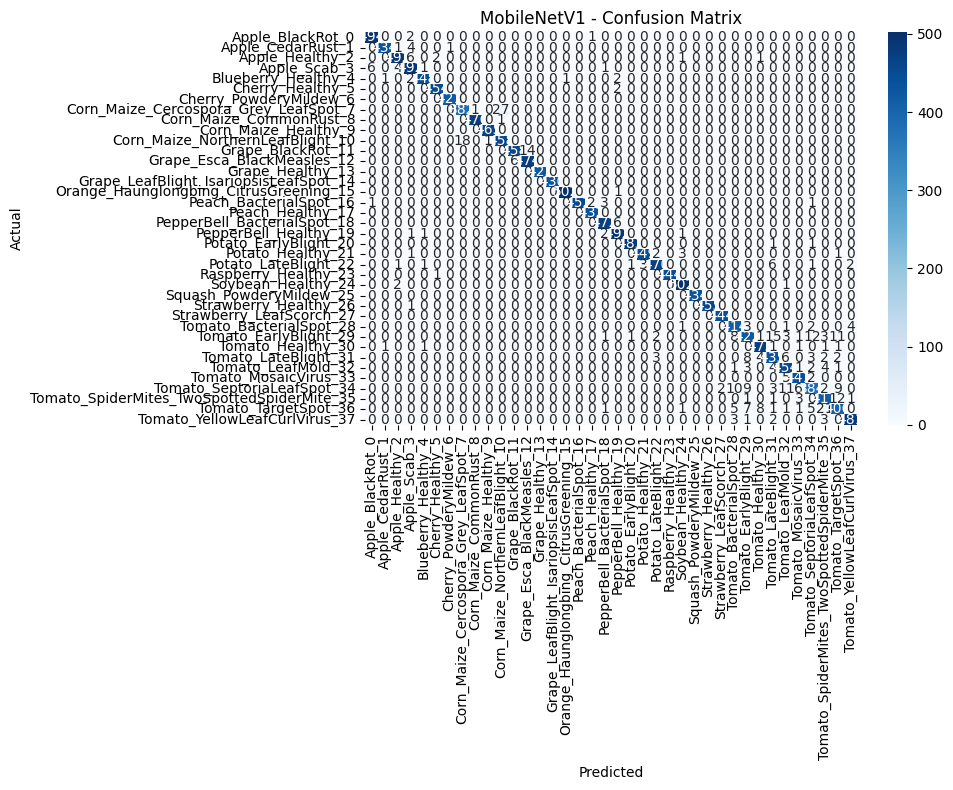

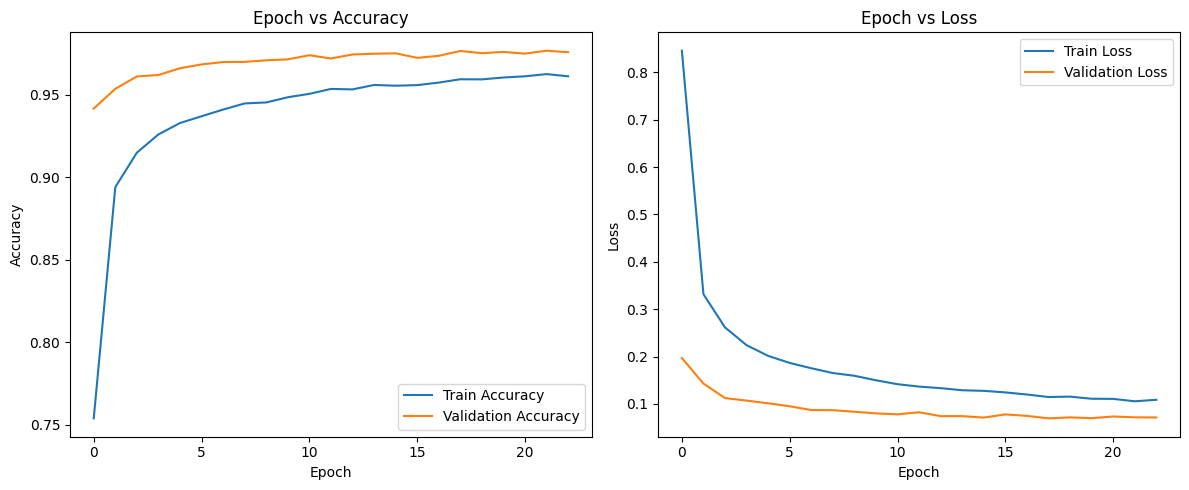

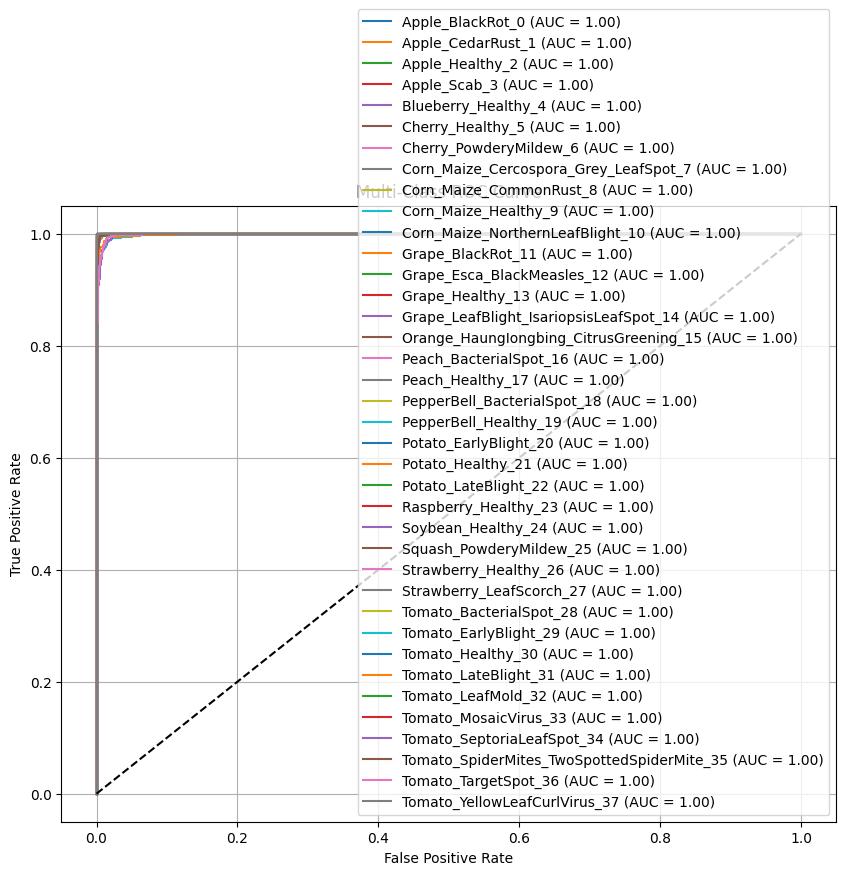

(<keras.callbacks.History at 0x1dda5bc74c0>,
 0.9766105167311632,
 0.976597036315612,
 0.9766105167311632,
 0.9765196270634916)

In [2]:
train_and_evaluate_model(MobileNet, "MobileNetV1")


=== Training MobileNetV2 ===
Epoch 1/25
733/733 - 176s - loss: 0.9172 - accuracy: 0.7327 - val_loss: 0.2696 - val_accuracy: 0.9226 - 176s/epoch - 240ms/step
Epoch 2/25
733/733 - 178s - loss: 0.4121 - accuracy: 0.8681 - val_loss: 0.1958 - val_accuracy: 0.9368 - 178s/epoch - 243ms/step
Epoch 3/25
733/733 - 178s - loss: 0.3377 - accuracy: 0.8910 - val_loss: 0.1737 - val_accuracy: 0.9462 - 178s/epoch - 243ms/step
Epoch 4/25
733/733 - 180s - loss: 0.2969 - accuracy: 0.9019 - val_loss: 0.1574 - val_accuracy: 0.9489 - 180s/epoch - 245ms/step
Epoch 5/25
733/733 - 183s - loss: 0.2686 - accuracy: 0.9108 - val_loss: 0.1395 - val_accuracy: 0.9546 - 183s/epoch - 249ms/step
Epoch 6/25
733/733 - 177s - loss: 0.2514 - accuracy: 0.9165 - val_loss: 0.1330 - val_accuracy: 0.9562 - 177s/epoch - 241ms/step
Epoch 7/25
733/733 - 179s - loss: 0.2323 - accuracy: 0.9218 - val_loss: 0.1345 - val_accuracy: 0.9560 - 179s/epoch - 245ms/step
Epoch 8/25
733/733 - 174s - loss: 0.2225 - accuracy: 0.9240 - val_loss: 0.

C:\ProgramData\anaconda3\envs\tf_cuda_env\lib\site-packages\keras\engine\functional.py:1410: CustomMaskWarning: Custom mask layers require a config and must override get_config. When loading, the custom mask layer must be passed to the custom_objects argument.
  layer_config = serialize_layer_fn(layer)


✅ Saved full model as MobileNetV2_full_model.h5

📊 Classification Report for MobileNetV2:
                                            precision    recall  f1-score   support

                          Apple_BlackRot_0       0.98      0.99      0.98       497
                         Apple_CedarRust_1       1.00      0.98      0.99       440
                           Apple_Healthy_2       0.99      0.99      0.99       502
                              Apple_Scab_3       0.97      0.98      0.97       504
                       Blueberry_Healthy_4       0.99      0.99      0.99       454
                          Cherry_Healthy_5       0.99      0.99      0.99       456
                    Cherry_PowderyMildew_6       1.00      1.00      1.00       421
     Corn_Maize_Cercospora_Grey_LeafSpot_7       0.96      0.89      0.92       410
                   Corn_Maize_CommonRust_8       1.00      1.00      1.00       477
                      Corn_Maize_Healthy_9       1.00      1.00      

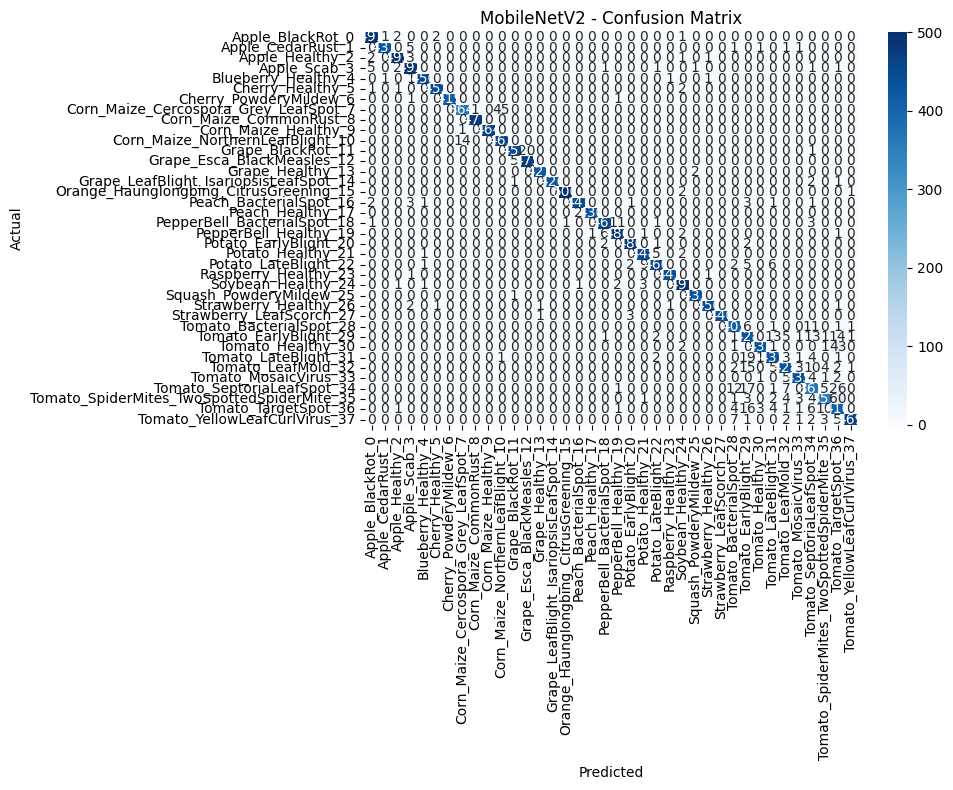

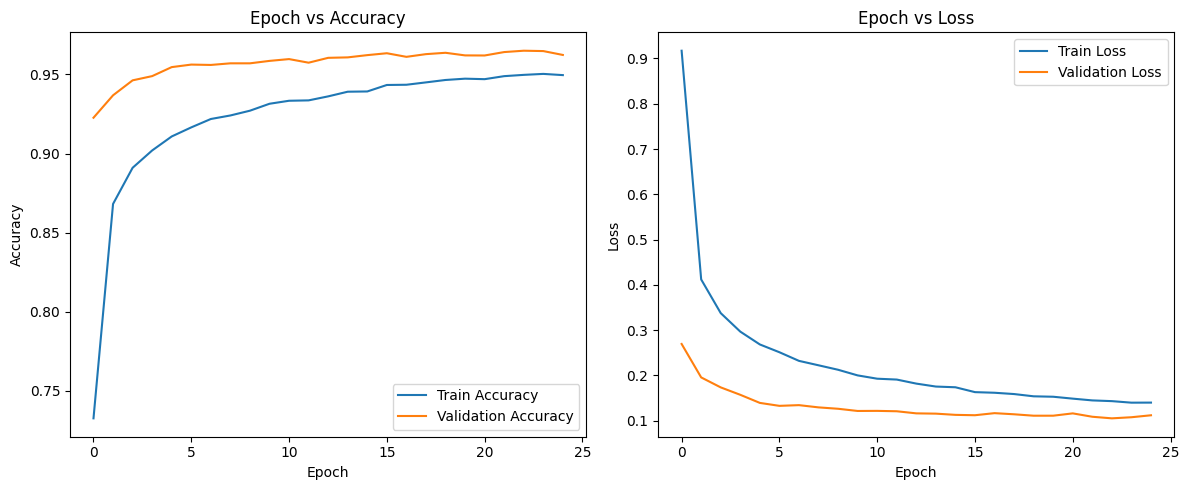

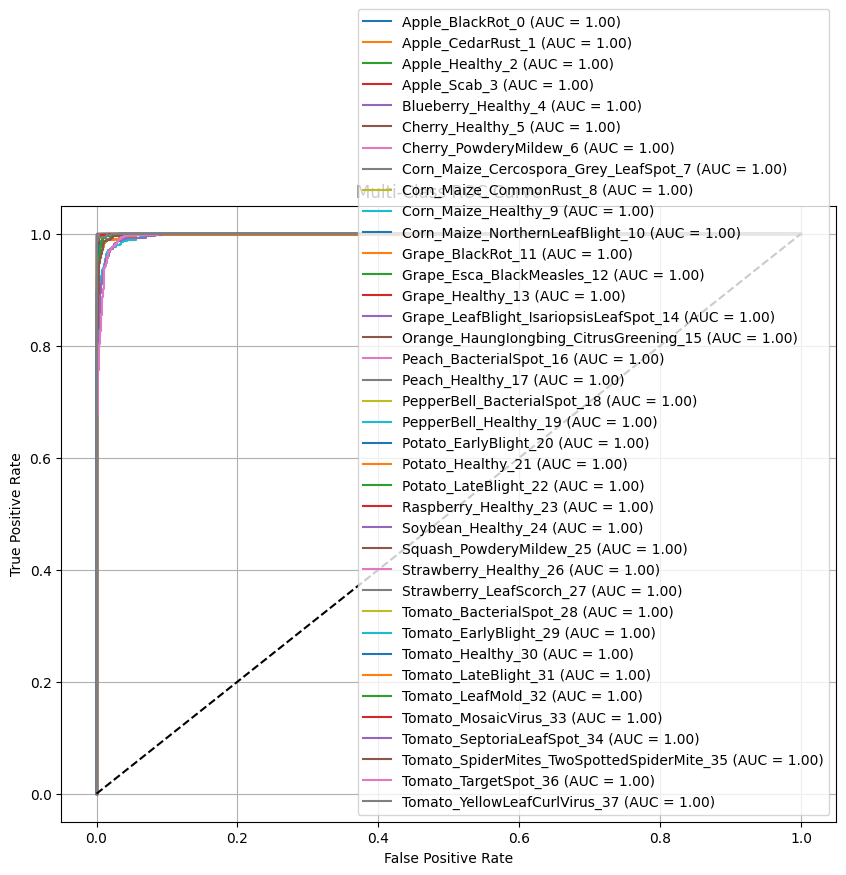

(<keras.callbacks.History at 0x1de3403e520>,
 0.9622695196904165,
 0.9641909190072692,
 0.9622695196904165,
 0.9627015051007538)

In [3]:
train_and_evaluate_model(MobileNetV2, "MobileNetV2")